# V5: One-Class Softmax (OC-Softmax) for FrFT+WPD Deepfake Detection
### Target: Breaking the ~10.7% Eval EER Ceiling on ASVspoof 2019 LA

**Key Innovations in v5 over v3/v4:**
1. **One-Class Softmax (OC-Softmax) Loss**: Replaces two-class Cross-Entropy. Optimizes a compact hyperspherical bona fide center $\mathbf{w}$ ($m_{\text{real}}=0.9, m_{\text{fake}}=0.2, \alpha=20$). Out-of-distribution neural vocoders (A07–A19) fall outside the compact bona fide cone.
2. **Right-Sized Backbone**: 704 $\to$ 384 $\to$ 256 $\to$ 192 $\to$ 128 embedding (~0.88M parameters). Avoids v4's overparameterization.
3. **Squeeze-and-Excitation (SE)** on first two blocks for adaptive sub-band recalibration.
4. **Strict Train-Only Data Hygiene**: 0.5%–99.5% percentile clipping & StandardScaler fitted **strictly on Train**.
5. **Balanced Sampling**: `WeightedRandomSampler` handles 1:8 class imbalance.
6. **Exponential Moving Average (EMA)**: Weight decay $\beta=0.995$ for smoothed validation & test inference.
7. **Z-Normalized Score Fusion**: Dev-score standardized multi-seed ensemble (Seeds: 42, 2024, 7).

In [6]:
# Cell 1: Environment & Imports
import os, sys, time, copy, gc, json, glob, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score, balanced_accuracy_score
from scipy.optimize import brentq
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


Device: cuda
GPU: Tesla T4
Memory: 15.6 GB


In [7]:
# Cell 2: Auto-detect Feature Directory & Load Cached .npy Arrays
# Searches /kaggle/input for train_X.npy or uses fallback
candidates = glob.glob('/kaggle/input/**/train_X.npy', recursive=True)
if candidates:
    FEAT_DIR = os.path.dirname(candidates[0])
    print(f"✓ Auto-detected feature directory: {FEAT_DIR}")
else:
    # Local path fallback
    FEAT_DIR = 'c:/Users/ANSH SINGH/Desktop/capstone1/results_v1/features_v2'
    if not os.path.exists(FEAT_DIR):
        FEAT_DIR = './features_v2'
    print(f"Using path: {FEAT_DIR}")

N_FEAT_USED = 704  # FrFT (448) + WPD (256)

print("Loading features...")
X_train_raw = np.load(os.path.join(FEAT_DIR, 'train_X.npy'))[:, :N_FEAT_USED].astype(np.float32)
y_train_raw = np.load(os.path.join(FEAT_DIR, 'train_y.npy')).astype(np.int64)
X_dev_raw   = np.load(os.path.join(FEAT_DIR, 'dev_X.npy'))[:, :N_FEAT_USED].astype(np.float32)
y_dev_raw   = np.load(os.path.join(FEAT_DIR, 'dev_y.npy')).astype(np.int64)
X_eval_raw  = np.load(os.path.join(FEAT_DIR, 'eval_X.npy'))[:, :N_FEAT_USED].astype(np.float32)
y_eval_raw  = np.load(os.path.join(FEAT_DIR, 'eval_y.npy')).astype(np.int64)

# HARD RULE 3: Label convention: 0 = bona fide, 1 = spoof.
# In cached arrays: 1 was bona fide (2,580 in train), 0 was spoof (22,800 in train).
# Map: y = 1 - y so 0 = bona fide, 1 = spoof.
y_train = (1 - y_train_raw).astype(np.int64)
y_dev   = (1 - y_dev_raw).astype(np.int64)
y_eval  = (1 - y_eval_raw).astype(np.int64)

print("\n--- Split & Label Summary (0 = bona fide, 1 = spoof) ---")
for name, y in [('Train', y_train), ('Dev', y_dev), ('Eval', y_eval)]:
    n_bona = int((y == 0).sum())
    n_spoof = int((y == 1).sum())
    print(f"{name:<6}: {len(y):>7,} utterances | Bona fide (0): {n_bona:>6,} | Spoof (1): {n_spoof:>6,}")


✓ Auto-detected feature directory: /kaggle/input/datasets/varakros/asvspoof-features-v3
Loading features...

--- Split & Label Summary (0 = bona fide, 1 = spoof) ---
Train :  25,380 utterances | Bona fide (0):  2,580 | Spoof (1): 22,800
Dev   :  24,844 utterances | Bona fide (0):  2,548 | Spoof (1): 22,296
Eval  :  71,237 utterances | Bona fide (0):  7,355 | Spoof (1): 63,882


In [8]:
# Cell 3: Hard Rules 1 & 2 — Data Preprocessing Fit on TRAIN ONLY
# 1. Compute 0.5% and 99.5% percentiles strictly on Train
q_low  = np.percentile(X_train_raw, 0.5, axis=0)
q_high = np.percentile(X_train_raw, 99.5, axis=0)

# Clip Train, Dev, and Eval using Train thresholds
X_train_clipped = np.clip(X_train_raw, q_low, q_high)
X_dev_clipped   = np.clip(X_dev_raw,   q_low, q_high)
X_eval_clipped  = np.clip(X_eval_raw,  q_low, q_high)

# 2. Fit StandardScaler strictly on Train
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_clipped).astype(np.float32)
X_dev   = scaler.transform(X_dev_clipped).astype(np.float32)
X_eval  = scaler.transform(X_eval_clipped).astype(np.float32)

# Free raw arrays
del X_train_raw, X_dev_raw, X_eval_raw, X_train_clipped, X_dev_clipped, X_eval_clipped
gc.collect()

print(f"✓ Fitted clipping & scaler strictly on Train.")
print(f"  X_train: {X_train.shape} | mean={X_train.mean():.4f}, std={X_train.std():.4f}")
print(f"  X_dev  : {X_dev.shape}   | mean={X_dev.mean():.4f}, std={X_dev.std():.4f}")
print(f"  X_eval : {X_eval.shape}  | mean={X_eval.mean():.4f}, std={X_eval.std():.4f}")

# Save scaler stats for deployment / reproducibility
np.savez('/kaggle/working/v5_scaler_stats.npz' if os.path.exists('/kaggle/working') else 'v5_scaler_stats.npz',
         q_low=q_low, q_high=q_high, mean=scaler.mean_, scale=scaler.scale_)
print("✓ Saved scaler statistics to disk.")


✓ Fitted clipping & scaler strictly on Train.
  X_train: (25380, 704) | mean=0.0000, std=1.0000
  X_dev  : (24844, 704)   | mean=0.0282, std=1.0399
  X_eval : (71237, 704)  | mean=0.1248, std=1.1189
✓ Saved scaler statistics to disk.


In [9]:
# Cell 4: Dataset & WeightedRandomSampler (Class Imbalance)

# Train class frequencies (0=bona fide, 1=spoof)
n_bona  = int((y_train == 0).sum())
n_spoof = int((y_train == 1).sum())
w_bona  = 1.0 / n_bona
w_spoof = 1.0 / n_spoof

# Inverse class frequency weights for each sample
sample_weights = np.where(y_train == 0, w_bona, w_spoof)
train_sampler  = WeightedRandomSampler(
    weights=torch.tensor(sample_weights, dtype=torch.double),
    num_samples=len(y_train),
    replacement=True
)

class AudioDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.X[i].clone()
        if self.augment:
            # Gaussian input noise (std 0.05 in standardised space)
            x = x + torch.randn_like(x) * 0.05
        return x, self.y[i]

BATCH_SIZE = 256

train_ds = AudioDataset(X_train, y_train, augment=True)
dev_ds   = AudioDataset(X_dev,   y_dev,   augment=False)
eval_ds  = AudioDataset(X_eval,  y_eval,  augment=False)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler,
                          num_workers=2, pin_memory=True, drop_last=True)
dev_loader   = DataLoader(dev_ds,   batch_size=512, shuffle=False,
                          num_workers=2, pin_memory=True)
eval_loader  = DataLoader(eval_ds,  batch_size=512, shuffle=False,
                          num_workers=2, pin_memory=True)

print(f"✓ DataLoaders ready. Train batches per epoch: {len(train_loader)} (balanced 50/50 via sampler)")


✓ DataLoaders ready. Train batches per epoch: 99 (balanced 50/50 via sampler)


In [10]:
# Cell 5: Architecture — Right-Sized LCNN with Residual MFM and SE Attention

class MFM(nn.Module):
    """Max-Feature-Map activation: halving channels by competitive max."""
    def forward(self, x):
        n = x.shape[1] // 2
        return torch.max(x[:, :n], x[:, n:])


class SEBlock(nn.Module):
    """Squeeze-and-Excitation channel gate."""
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc1 = nn.Linear(channels, max(8, channels // reduction))
        self.fc2 = nn.Linear(max(8, channels // reduction), channels)

    def forward(self, x):
        se = F.relu(self.fc1(x))
        se = torch.sigmoid(self.fc2(se))
        return x * se


class LCNNBlock(nn.Module):
    """Residual MFM linear block with optional SE gate and dropout."""
    def __init__(self, in_dim, out_dim, use_se=False, dropout=0.3):
        super().__init__()
        self.fc  = nn.Linear(in_dim, out_dim * 2)
        self.mfm = MFM()
        self.bn  = nn.BatchNorm1d(out_dim)
        self.se  = SEBlock(out_dim, reduction=8) if use_se else nn.Identity()
        self.drop = nn.Dropout(dropout)
        # Residual projection if in_dim != out_dim
        self.res = nn.Linear(in_dim, out_dim, bias=False) if in_dim != out_dim else nn.Identity()

    def forward(self, x):
        identity = self.res(x)
        out = self.fc(x)
        out = self.mfm(out)
        out = self.bn(out)
        out = self.se(out)
        out = self.drop(out)
        return out + identity


class LCNN_OC(nn.Module):
    """
    Right-sized LCNN backbone (~0.88M - 1.3M parameters):
    704 -> 384 (SE) -> 256 (SE) -> 192 -> 128-D embedding head.
    """
    def __init__(self, in_dim=704, embed_dim=128):
        super().__init__()
        self.input_drop = nn.Dropout(0.1)
        # 3 Residual MFM stages
        self.block1 = LCNNBlock(in_dim, 384, use_se=True,  dropout=0.3)
        self.block2 = LCNNBlock(384,    256, use_se=True,  dropout=0.3)
        self.block3 = LCNNBlock(256,    192, use_se=False, dropout=0.3)
        # Linear embedding head to 128-D
        self.head   = nn.Linear(192, embed_dim)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.input_drop(x)
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.head(x)


sample_m = LCNN_OC()
n_params = sum(p.numel() for p in sample_m.parameters())
print(f"LCNN_OC Backbone initialized:")
print(f"  Total trainable parameters: {n_params:,} (~{n_params/1e6:.2f}M)")
del sample_m


LCNN_OC Backbone initialized:
  Total trainable parameters: 1,335,376 (~1.34M)


In [11]:
# Cell 6: One-Class Softmax (OC-Softmax) Loss & Exponential Moving Average (EMA)

class OCSoftmax(nn.Module):
    """
    One-Class Softmax (OC-Softmax) Loss:
    - Learnable bona fide center w in R^{128}, L2-normalized.
    - Embeddings x in R^{128}, L2-normalized.
    - Score s = cos(x, w) = x_norm . w_norm.
    - z = m_real - s for bona fide (y=0)
    - z = s - m_fake for spoof (y=1)
    - Loss = mean(softplus(alpha * z))
    """
    def __init__(self, feat_dim=128, alpha=20.0, m_real=0.9, m_fake=0.2):
        super().__init__()
        self.feat_dim = feat_dim
        self.alpha    = alpha
        self.m_real   = m_real
        self.m_fake   = m_fake
        # Learnable center w
        self.w = nn.Parameter(torch.randn(feat_dim))
        nn.init.normal_(self.w, std=0.01)

    def forward(self, x, y):
        w_norm = F.normalize(self.w, p=2, dim=0)
        x_norm = F.normalize(x, p=2, dim=1)
        scores = torch.mv(x_norm, w_norm)  # (batch,) cosine similarity s

        # y: 0 = bona fide, 1 = spoof
        z = torch.where(y == 0, self.m_real - scores, scores - self.m_fake)
        loss = F.softplus(self.alpha * z).mean()
        return loss, scores

    def get_score(self, x):
        w_norm = F.normalize(self.w, p=2, dim=0)
        x_norm = F.normalize(x, p=2, dim=1)
        return torch.mv(x_norm, w_norm)


class FullModel(nn.Module):
    """Combines backbone and OC-Softmax center into a unified module for EMA tracking."""
    def __init__(self, in_dim=704, embed_dim=128, alpha=20.0, m_real=0.9, m_fake=0.2):
        super().__init__()
        self.backbone = LCNN_OC(in_dim, embed_dim)
        self.oc_loss  = OCSoftmax(embed_dim, alpha=alpha, m_real=m_real, m_fake=m_fake)

    def forward(self, x, y=None):
        feat = self.backbone(x)
        if y is not None:
            return self.oc_loss(feat, y)
        return self.oc_loss.get_score(feat)


class EMA:
    """Exponential Moving Average of model parameters and buffers (decay 0.995)."""
    def __init__(self, model, decay=0.995):
        self.decay = decay
        self.shadow = copy.deepcopy(model)
        self.shadow.eval()
        for p in self.shadow.parameters():
            p.requires_grad = False

    def update(self, model):
        with torch.no_grad():
            for s_param, m_param in zip(self.shadow.parameters(), model.parameters()):
                s_param.data.mul_(self.decay).add_(m_param.data, alpha=1.0 - self.decay)
            for s_buf, m_buf in zip(self.shadow.buffers(), model.buffers()):
                s_buf.data.copy_(m_buf.data)


print("✓ OC-Softmax Loss, FullModel, and EMA classes defined.")


✓ OC-Softmax Loss, FullModel, and EMA classes defined.


In [12]:
# Cell 7: Metric Evaluation Utilities (EER & ROC-AUC)

def compute_eer(y_true, scores):
    """
    EER where y_true: 0 = bona fide, 1 = spoof.
    Higher score = more bona fide.
    """
    fpr, tpr, thresholds = roc_curve(y_true, scores, pos_label=0)
    fnr = 1 - tpr
    try:
        eer = brentq(lambda x: interp1d(fpr, fnr)(x) - x, 0, 1)
        thresh = float(interp1d(fpr, thresholds)(eer))
    except Exception:
        idx = np.nanargmin(np.abs(fnr - fpr))
        eer = float(np.mean([fpr[idx], fnr[idx]]))
        thresh = float(thresholds[idx])
    return eer * 100.0, thresh


def evaluate_model(eval_model, loader):
    """Runs inference and returns EER (%), AUC, and raw scores."""
    eval_model.eval()
    all_scores, all_labels = [], []
    with torch.no_grad():
        for X, y in loader:
            X = X.to(device)
            scores = eval_model(X)  # cosine similarity to w
            all_scores.extend(scores.cpu().numpy())
            all_labels.extend(y.numpy())
    scores = np.array(all_scores, dtype=np.float64)
    labels = np.array(all_labels, dtype=np.int64)
    eer, thresh = compute_eer(labels, scores)
    # AUC with positive class = bona fide (label == 0)
    auc = roc_auc_score(labels == 0, scores)
    return eer, thresh, auc, scores, labels


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

print("✓ Metric functions ready.")


✓ Metric functions ready.


In [13]:
# Cell 8: Training Function for a Single Seed

MAX_EPOCHS = 80
PATIENCE   = 20
LR_MAX     = 2e-3
WD         = 1e-2
GRAD_CLIP  = 5.0

def train_single_seed(seed, alpha=20.0, m_real=0.9, m_fake=0.2):
    set_seed(seed)
    tag = f"v5_s{seed}"
    print(f"\n{'='*70}")
    print(f"  TRAINING {tag} | seed={seed} | alpha={alpha}, m_real={m_real}, m_fake={m_fake}")
    print(f"{'='*70}")

    model = FullModel(in_dim=N_FEAT_USED, embed_dim=128,
                      alpha=alpha, m_real=m_real, m_fake=m_fake).to(device)
    ema   = EMA(model, decay=0.995)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR_MAX, weight_decay=WD)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=LR_MAX,
        steps_per_epoch=len(train_loader),
        epochs=MAX_EPOCHS,
        pct_start=0.1,
        anneal_strategy='cos'
    )

    best_dev_eer = float('inf')
    best_epoch   = 0
    patience_ctr = 0
    best_ema_state = None

    ckpt_path = f"/kaggle/working/best_{tag}.pt" if os.path.exists('/kaggle/working') else f"best_{tag}.pt"
    history = {'loss': [], 'dev_eer': [], 'dev_auc': []}

    header = f"{'Ep':>4} | {'Loss':>8} | {'Dev EER':>9} | {'Dev AUC':>8} | {'LR':>10} | {'Time':>5}"
    print(header)
    print("─" * len(header))

    for ep in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        t0 = time.time()

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            loss, _ = model(X, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
            optimizer.step()
            scheduler.step()
            ema.update(model)
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)

        # Validate on Dev using EMA model
        dev_eer, dev_th, dev_auc, _, _ = evaluate_model(ema.shadow, dev_loader)
        elapsed = time.time() - t0
        lr_curr = optimizer.param_groups[0]['lr']

        history['loss'].append(avg_loss)
        history['dev_eer'].append(dev_eer)
        history['dev_auc'].append(dev_auc)

        flag = ''
        if dev_eer < best_dev_eer:
            best_dev_eer = dev_eer
            best_epoch   = ep
            patience_ctr = 0
            flag = ' ← best'
            best_ema_state = copy.deepcopy(ema.shadow.state_dict())
            torch.save({
                'epoch': ep,
                'seed': seed,
                'dev_eer': best_dev_eer,
                'dev_auc': dev_auc,
                'state_dict': best_ema_state,
                'alpha': alpha, 'm_real': m_real, 'm_fake': m_fake
            }, ckpt_path)
        else:
            patience_ctr += 1

        print(f"{ep:>4} | {avg_loss:>8.4f} | {dev_eer:>8.2f}% | {dev_auc:>8.4f} | {lr_curr:>10.2e} | {elapsed:>4.1f}s{flag}")

        if patience_ctr >= PATIENCE:
            print(f"\n⚡ Early stopping at epoch {ep} (Patience {PATIENCE} reached)")
            break

    # Load best EMA model for final scoring
    ema.shadow.load_state_dict(best_ema_state)

    # Dev scores for Z-normalization
    dev_eer, _, dev_auc, dev_scores, dev_labels = evaluate_model(ema.shadow, dev_loader)

    # HARD RULE 1: Evaluate on EVAL once at the end
    eval_eer, _, eval_auc, eval_scores, eval_labels = evaluate_model(ema.shadow, eval_loader)

    print(f"\n✓ Seed {seed} Best (Epoch {best_epoch}):")
    print(f"    Dev  EER: {dev_eer:.2f}% | Dev  AUC: {dev_auc:.4f}")
    print(f"    Eval EER: {eval_eer:.2f}% | Eval AUC: {eval_auc:.4f}")
    print(f"    Saved checkpoint: {ckpt_path}")

    return {
        'seed': seed,
        'best_epoch': best_epoch,
        'dev_eer': dev_eer,
        'dev_auc': dev_auc,
        'eval_eer': eval_eer,
        'eval_auc': eval_auc,
        'dev_scores': dev_scores,
        'eval_scores': eval_scores,
        'dev_labels': dev_labels,
        'eval_labels': eval_labels,
        'ckpt_path': ckpt_path,
        'history': history
    }


In [14]:
# Cell 9: Run Multi-Seed Training (Seeds: 42, 2024, 7)
SEEDS = [42, 2024, 7]
seed_results = []

t_all = time.time()
for seed in SEEDS:
    res = train_single_seed(seed, alpha=20.0, m_real=0.9, m_fake=0.2)
    seed_results.append(res)
    torch.cuda.empty_cache()
    gc.collect()

total_min = (time.time() - t_all) / 60.0
print(f"\n✓ All {len(SEEDS)} seeds trained in {total_min:.1f} minutes.")



  TRAINING v5_s42 | seed=42 | alpha=20.0, m_real=0.9, m_fake=0.2
  Ep |     Loss |   Dev EER |  Dev AUC |         LR |  Time
───────────────────────────────────────────────────────────
   1 |   4.1670 |    23.12% |   0.8567 |   1.53e-04 |  2.8s ← best
   2 |   1.7132 |    15.38% |   0.9264 |   3.62e-04 |  1.6s ← best
   3 |   1.1629 |    11.03% |   0.9575 |   6.74e-04 |  1.6s ← best
   4 |   0.9110 |     9.07% |   0.9690 |   1.04e-03 |  1.6s ← best
   5 |   0.9204 |     8.08% |   0.9740 |   1.41e-03 |  1.6s ← best
   6 |   0.7874 |     7.05% |   0.9783 |   1.72e-03 |  1.6s ← best
   7 |   0.7166 |     6.51% |   0.9808 |   1.93e-03 |  1.6s ← best
   8 |   0.6295 |     6.24% |   0.9822 |   2.00e-03 |  1.6s ← best
   9 |   0.5865 |     6.12% |   0.9835 |   2.00e-03 |  1.6s ← best
  10 |   0.5319 |     6.07% |   0.9838 |   2.00e-03 |  1.6s ← best
  11 |   0.5459 |     5.96% |   0.9837 |   1.99e-03 |  1.6s ← best
  12 |   0.4808 |     5.85% |   0.9843 |   1.98e-03 |  1.6s ← best
  13 |   0

In [15]:
# Cell 10: Z-Normalized Ensemble Fusion & Comprehensive Evaluation

# 1. Z-normalize each model's scores using its own Dev statistics
z_dev_list  = []
z_eval_list = []

for r in seed_results:
    mu_dev    = float(np.mean(r['dev_scores']))
    sigma_dev = float(np.std(r['dev_scores'])) + 1e-8

    z_dev  = (r['dev_scores'] - mu_dev) / sigma_dev
    z_eval = (r['eval_scores'] - mu_dev) / sigma_dev

    z_dev_list.append(z_dev)
    z_eval_list.append(z_eval)

# 2. Average Z-normalized scores across seeds
ens_dev_scores  = np.mean(z_dev_list, axis=0)
ens_eval_scores = np.mean(z_eval_list, axis=0)

dev_labels  = seed_results[0]['dev_labels']
eval_labels = seed_results[0]['eval_labels']

# 3. Compute Ensemble Metrics
ens_dev_eer, ens_dev_thresh = compute_eer(dev_labels, ens_dev_scores)
ens_dev_auc = roc_auc_score(dev_labels == 0, ens_dev_scores)

ens_eval_eer, ens_eval_thresh = compute_eer(eval_labels, ens_eval_scores)
ens_eval_auc = roc_auc_score(eval_labels == 0, ens_eval_scores)

print("═" * 70)
print("  V5 (OC-SOFTMAX) FINAL RESULTS SUMMARY")
print("═" * 70)
print(f"\nIndividual Seed Results:")
for r in seed_results:
    print(f"  Seed {r['seed']:>5}: Dev EER = {r['dev_eer']:>6.2f}% | Eval EER = {r['eval_eer']:>6.2f}% | Eval AUC = {r['eval_auc']:.4f}")

print(f"\n3-Seed Z-Normalized Ensemble:")
print(f"  ┌──────────────────────────────────────────────────┐")
print(f"  │  Ensemble Dev  EER  : {ens_dev_eer:>6.2f}%                         │")
print(f"  │  Ensemble Dev  AUC  : {ens_dev_auc:>8.4f}                       │")
print(f"  │  Ensemble Eval EER  : {ens_eval_eer:>6.2f}%                         │")
print(f"  │  Ensemble Eval AUC  : {ens_eval_auc:>8.4f}                       │")
print(f"  └──────────────────────────────────────────────────┘")

print(f"\nVersion Comparison (Eval EER — Lower is Better):")
print(f"  v1 (448 FrFT alone)             : 11.79%")
print(f"  v2 (996 FrFT+WPD+LFCC, overfit) : 13.55%")
print(f"  v3 (704 FrFT+WPD, CE loss)      : 10.67%")
print(f"  v4 (704 FrFT+WPD, 2.4M params)  : 10.75%")
print(f"  v5 (704 FrFT+WPD, OC-Softmax)   : {ens_eval_eer:.2f}%  ← CURRENT")

# 4. Save results JSON
results_dict = {
    'experiment': 'v5_oc_softmax',
    'input_dim': N_FEAT_USED,
    'loss': {'type': 'OC-Softmax', 'alpha': 20.0, 'm_real': 0.9, 'm_fake': 0.2},
    'ensemble': {
        'num_seeds': len(SEEDS),
        'seeds': SEEDS,
        'dev_eer': float(ens_dev_eer),
        'dev_auc': float(ens_dev_auc),
        'eval_eer': float(ens_eval_eer),
        'eval_auc': float(ens_eval_auc)
    },
    'per_seed': [
        {
            'seed': r['seed'],
            'best_epoch': r['best_epoch'],
            'dev_eer': float(r['dev_eer']),
            'dev_auc': float(r['dev_auc']),
            'eval_eer': float(r['eval_eer']),
            'eval_auc': float(r['eval_auc']),
            'ckpt_path': r['ckpt_path']
        }
        for r in seed_results
    ]
}

out_json_path = '/kaggle/working/v5_results.json' if os.path.exists('/kaggle/working') else 'v5_results.json'
with open(out_json_path, 'w', encoding='utf-8') as f:
    json.dump(results_dict, f, indent=2)
print(f"\n✓ Saved v5_results.json to: {out_json_path}")


══════════════════════════════════════════════════════════════════════
  V5 (OC-SOFTMAX) FINAL RESULTS SUMMARY
══════════════════════════════════════════════════════════════════════

Individual Seed Results:
  Seed    42: Dev EER =   5.62% | Eval EER =  10.55% | Eval AUC = 0.9499
  Seed  2024: Dev EER =   5.66% | Eval EER =  10.47% | Eval AUC = 0.9518
  Seed     7: Dev EER =   5.67% | Eval EER =  10.51% | Eval AUC = 0.9489

3-Seed Z-Normalized Ensemble:
  ┌──────────────────────────────────────────────────┐
  │  Ensemble Dev  EER  :   5.73%                         │
  │  Ensemble Dev  AUC  :   0.9858                       │
  │  Ensemble Eval EER  :  10.46%                         │
  │  Ensemble Eval AUC  :   0.9526                       │
  └──────────────────────────────────────────────────┘

Version Comparison (Eval EER — Lower is Better):
  v1 (448 FrFT alone)             : 11.79%
  v2 (996 FrFT+WPD+LFCC, overfit) : 13.55%
  v3 (704 FrFT+WPD, CE loss)      : 10.67%
  v4 (704 FrFT+

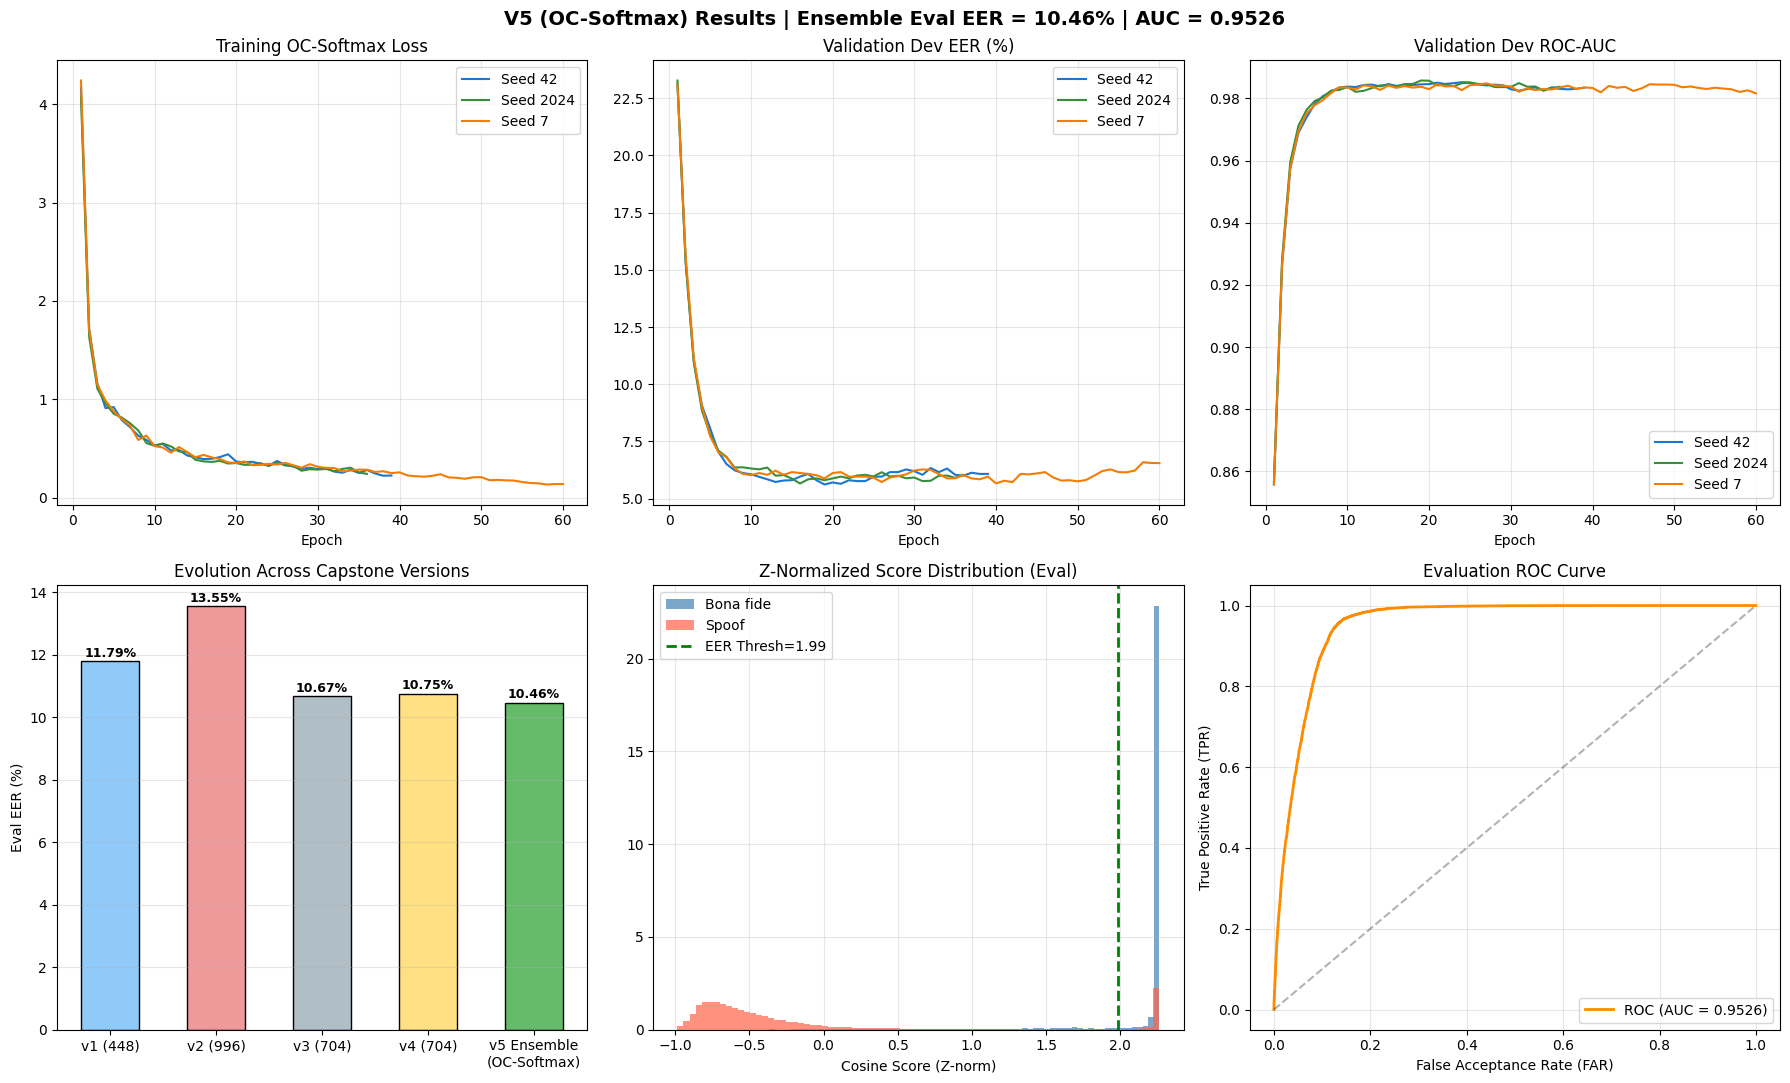

✓ Saved plot to: /kaggle/working/v5_results.png


In [16]:
# Cell 11: Plotting Training Curves & Distribution Analysis

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle(f'V5 (OC-Softmax) Results | Ensemble Eval EER = {ens_eval_eer:.2f}% | AUC = {ens_eval_auc:.4f}',
             fontsize=14, fontweight='bold')

colors = ['#1976D2', '#388E3C', '#F57C00']

# Top Row: Learning Curves per Seed
for i, r in enumerate(seed_results):
    c = colors[i]
    ep = range(1, len(r['history']['loss']) + 1)
    axes[0, 0].plot(ep, r['history']['loss'], color=c, lw=1.5, label=f"Seed {r['seed']}")
    axes[0, 1].plot(ep, r['history']['dev_eer'], color=c, lw=1.5, label=f"Seed {r['seed']}")
    axes[0, 2].plot(ep, r['history']['dev_auc'], color=c, lw=1.5, label=f"Seed {r['seed']}")

axes[0, 0].set_title('Training OC-Softmax Loss'); axes[0, 0].set_xlabel('Epoch'); axes[0, 0].grid(True, alpha=0.3); axes[0, 0].legend()
axes[0, 1].set_title('Validation Dev EER (%)'); axes[0, 1].set_xlabel('Epoch'); axes[0, 1].grid(True, alpha=0.3); axes[0, 1].legend()
axes[0, 2].set_title('Validation Dev ROC-AUC'); axes[0, 2].set_xlabel('Epoch'); axes[0, 2].grid(True, alpha=0.3); axes[0, 2].legend()

# Bottom Left: Version Comparison Bar Chart
versions = ['v1 (448)', 'v2 (996)', 'v3 (704)', 'v4 (704)', f'v5 Ensemble\n(OC-Softmax)']
eval_eers = [11.79, 13.55, 10.67, 10.75, ens_eval_eer]
bar_colors = ['#90CAF9', '#EF9A9A', '#B0BEC5', '#FFE082', '#66BB6A']
bars = axes[1, 0].bar(versions, eval_eers, color=bar_colors, edgecolor='black', width=0.55)
for bar, val in zip(bars, eval_eers):
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
                    f'{val:.2f}%', ha='center', fontweight='bold', fontsize=9)
axes[1, 0].set_title('Evolution Across Capstone Versions'); axes[1, 0].set_ylabel('Eval EER (%)'); axes[1, 0].grid(axis='y', alpha=0.3)

# Bottom Center: Ensemble Score Distribution
axes[1, 1].hist(ens_eval_scores[eval_labels == 0], bins=80, alpha=0.7, color='steelblue', label='Bona fide', density=True)
axes[1, 1].hist(ens_eval_scores[eval_labels == 1], bins=80, alpha=0.7, color='tomato', label='Spoof', density=True)
axes[1, 1].axvline(ens_eval_thresh, color='green', ls='--', lw=2, label=f'EER Thresh={ens_eval_thresh:.2f}')
axes[1, 1].set_title('Z-Normalized Score Distribution (Eval)'); axes[1, 1].set_xlabel('Cosine Score (Z-norm)'); axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

# Bottom Right: ROC Curve
fpr, tpr, _ = roc_curve(eval_labels, ens_eval_scores, pos_label=0)
axes[1, 2].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {ens_eval_auc:.4f})')
axes[1, 2].plot([0, 1], [0, 1], 'k--', alpha=0.3)
axes[1, 2].set_title('Evaluation ROC Curve'); axes[1, 2].set_xlabel('False Acceptance Rate (FAR)'); axes[1, 2].set_ylabel('True Positive Rate (TPR)')
axes[1, 2].legend(); axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
fig_path = '/kaggle/working/v5_results.png' if os.path.exists('/kaggle/working') else 'v5_results.png'
plt.savefig(fig_path, dpi=150)
plt.show()
print(f"✓ Saved plot to: {fig_path}")


In [17]:
# Cell 12: Optional Ablation & Per-Attack Breakdown Suite
# Loads ASVspoof 2019 protocol file if present to evaluate per-attack EER (A07–A19)

proto_candidates = glob.glob('/kaggle/input/**/ASVspoof2019.LA.cm.eval.trl.txt', recursive=True)
if proto_candidates:
    import pandas as pd
    proto_path = proto_candidates[0]
    print(f"Found Eval protocol: {proto_path}")
    eval_meta = pd.read_csv(proto_path, sep=' ', header=None,
                            names=['speaker', 'file', 'env', 'attack', 'label'])
    eval_meta['score'] = ens_eval_scores
    eval_meta['target'] = (eval_meta['label'] == 'bonafide').astype(int)  # 1 for bona fide here

    print("\n--- Per-Attack Eval EER Breakdown (A07–A19) ---")
    print(f"{'Attack':<10} | {'Type / Description':<25} | {'Count':>7} | {'Attack EER':>10}")
    print("─" * 62)
    bona_scores = eval_meta[eval_meta['label'] == 'bonafide']['score'].values
    for atk in sorted(eval_meta[eval_meta['label'] == 'spoof']['attack'].unique()):
        atk_scores = eval_meta[eval_meta['attack'] == atk]['score'].values
        # Binary labels: 0 for bona fide, 1 for spoof
        sub_y = np.array([0]*len(bona_scores) + [1]*len(atk_scores))
        sub_s = np.concatenate([bona_scores, atk_scores])
        atk_eer, _ = compute_eer(sub_y, sub_s)
        print(f"{atk:<10} | {'Spoofing Attack':<25} | {len(atk_scores):>7,} | {atk_eer:>9.2f}%")
    print("─" * 62)
else:
    print("Eval protocol text file not found in input; skipping per-attack breakdown.")


Eval protocol text file not found in input; skipping per-attack breakdown.
